# BÀI THỰC HÀNH 3: MẠNG NEURAL HỒI QUY CHO BÀI TOÁN PHÂN LOẠI VĂN BẢN VÀ GÁN NHÃN CHUỖI

## BỘ DỮ LIỆU UIT-VSFC

#### Kiểm tra đường dẫn

In [217]:
import os
import torch
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import random
import time
import torch.nn as nn
import torch.optim as optim
from collections import Counter
import torch.nn.functional as F

print(os.listdir("/kaggle/input/datasets/xuancuong1019/uit-vsfc"))

['UIT-VSFC-dev.json', 'UIT-VSFC-test.json', 'UIT-VSFC-train.json']


#### Kiểm tra kích thước dữ liệu

In [218]:
DATA_DIR = "/kaggle/input/datasets/xuancuong1019/uit-vsfc"

uit_train_df = pd.read_json(f"{DATA_DIR}/UIT-VSFC-train.json")
uit_dev_df = pd.read_json(f"{DATA_DIR}/UIT-VSFC-dev.json")
uit_test_df = pd.read_json(f"{DATA_DIR}/UIT-VSFC-test.json")

print("Train:", uit_train_df.shape)
print("Dev:", uit_dev_df.shape)
print("Test:", uit_test_df.shape)

Train: (11426, 3)
Dev: (1583, 3)
Test: (3166, 3)


#### Kiểm tra phân phối nhãn

In [219]:
print(uit_train_df['sentiment'].value_counts())
print("\nSố lượng nhãn:", uit_train_df['sentiment'].nunique())

sentiment
positive    5643
negative    5325
neutral      458
Name: count, dtype: int64

Số lượng nhãn: 3


#### Mã hóa sentiment

In [220]:
label2id = {'negative': 0, 'neutral': 1, 'positive': 2}

uit_train_df['label'] = uit_train_df['sentiment'].map(label2id)
uit_dev_df['label'] = uit_dev_df['sentiment'].map(label2id)
uit_test_df['label'] = uit_test_df['sentiment'].map(label2id)

#### Tokenization bằng underthesea

In [221]:
!pip install underthesea

In [222]:
from underthesea import word_tokenize

def tokenize(text):
    return word_tokenize(str(text).lower())

uit_train_df['tokens'] = uit_train_df['sentence'].apply(tokenize)
uit_dev_df['tokens'] = uit_dev_df['sentence'].apply(tokenize)
uit_test_df['tokens'] = uit_test_df['sentence'].apply(tokenize)


#### Thống kê độ dài câu (số từ) sau khi tokenize để chọn max_length

In [273]:
train_lengths = uit_train_df['tokens'].apply(len)
print(train_lengths.describe())
print(train_lengths.quantile([0.90, 0.95, 0.99]))

count    11426.000000
mean        11.151147
std          8.080817
min          2.000000
25%          6.000000
50%          9.000000
75%         14.000000
max        122.000000
Name: tokens, dtype: float64
0.90    21.00
0.95    26.75
0.99    42.00
Name: tokens, dtype: float64


#### Khảo sát dataset chọn min_freq

In [224]:
token_freq = Counter(token for tokens in uit_train_df['tokens'] for token in tokens)
total_tokens = sum(token_freq.values())
unique_tokens = len(token_freq)

singletons = sum(
    1 for freq in token_freq.values()
    if freq == 1
)

print("GENERAL STATISTICS")
print(f"Total token occurrences: {total_tokens:,}")
print(f"Unique tokens: {unique_tokens:,}")
print(f"Tokens appearing once: {singletons:,}")

print("VOCABULARY SIZE AND TOKEN COVERAGE")

thresholds = [1, 2, 3, 5, 10]

for min_freq in thresholds:
    vocab_size = sum(1 for freq in token_freq.values() if freq >= min_freq)
    retained_tokens = sum(freq for freq in token_freq.values() if freq >= min_freq)
    removed_vocab = unique_tokens - vocab_size
    coverage = retained_tokens / total_tokens * 100

    print(
        f"min_freq={min_freq:<2} | "
        f"Vocab size={vocab_size:>8,} | "
        f"Removed={removed_vocab:>7,} | "
        f"Coverage={coverage:.2f}%"
    )


GENERAL STATISTICS
Total token occurrences: 127,413
Unique tokens: 4,009
Tokens appearing once: 1,932
VOCABULARY SIZE AND TOKEN COVERAGE
min_freq=1  | Vocab size=   4,009 | Removed=      0 | Coverage=100.00%
min_freq=2  | Vocab size=   2,077 | Removed=  1,932 | Coverage=98.48%
min_freq=3  | Vocab size=   1,611 | Removed=  2,398 | Coverage=97.75%
min_freq=5  | Vocab size=   1,217 | Removed=  2,792 | Coverage=96.70%
min_freq=10 | Vocab size=     839 | Removed=  3,170 | Coverage=94.74%


#### Xây dựng từ điển

In [225]:
PAD, UNK = 0, 1
MIN_FREQ = 2
MAX_LENGTH = 35

def build_vocab(sequences, min_freq=MIN_FREQ):
    freq = Counter(token for tokens in sequences for token in tokens)
    tokens = sorted(token for token, count in freq.items() if count >= min_freq)
    return {"<pad>": PAD, "<unk>": UNK, **{token: idx + 2 for idx, token in enumerate(tokens)}}
    
vocab = build_vocab(uit_train_df['tokens'])
example = tokenize("giảng viên dạy rất hay")
print("Token minh họa:", example)


Token minh họa: ['giảng viên', 'dạy', 'rất', 'hay']


#### Encoding 

In [226]:
def encode(tokens, mapping):
    return [mapping.get(token, UNK) for token in tokens] or [UNK]

uit_train_df['input_ids'] = uit_train_df['tokens'].apply(lambda tokens: encode(tokens, vocab))
uit_dev_df['input_ids'] = uit_dev_df['tokens'].apply(lambda tokens: encode(tokens, vocab))
uit_test_df['input_ids'] = uit_test_df['tokens'].apply(lambda tokens: encode(tokens, vocab))

print("Tokens:", uit_train_df['tokens'].iloc[0])
print("Input IDs:", uit_train_df['input_ids'].iloc[0])
print("Label:", uit_train_df['sentiment'].iloc[0])

Tokens: ['slide', 'giáo trình', 'đầy đủ', '.']
Input IDs: [1331, 503, 1995, 10]
Label: positive


#### Padding/Truncation

In [227]:
def pad_truncate(input_ids, max_length=MAX_LENGTH):
    if len(input_ids) < max_length:
        input_ids = input_ids + [PAD] * (max_length - len(input_ids))   # PAD ở cuối, cần cho pack_padded_sequence
    elif len(input_ids) > max_length:
        input_ids = input_ids[:max_length]
    return input_ids

uit_train_df['input_ids'] = uit_train_df['input_ids'].apply(pad_truncate)
uit_dev_df['input_ids'] = uit_dev_df['input_ids'].apply(pad_truncate)
uit_test_df['input_ids'] = uit_test_df['input_ids'].apply(pad_truncate)

#### Khởi tạo dataset

In [228]:
from torch.utils.data import Dataset

class uit_vsfc(Dataset):
    def __init__(self, dataframe):
        self.input_ids = dataframe['input_ids'].tolist()
        self.label = dataframe['label'].tolist()

    def __len__(self):
        return len(self.label)

    def __getitem__(self, idx):
        return (
            torch.tensor(self.input_ids[idx], dtype=torch.long),
            torch.tensor(self.label[idx], dtype=torch.long)
        )

uit_train_dataset = uit_vsfc(uit_train_df)
uit_dev_dataset = uit_vsfc(uit_dev_df)
uit_test_dataset = uit_vsfc(uit_test_df)

#### DataLoader

In [229]:
from torch.utils.data import DataLoader

BATCH_SIZE = 32

train_loader = DataLoader(uit_train_dataset, batch_size=BATCH_SIZE, shuffle=True)
dev_loader = DataLoader(uit_dev_dataset, batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(uit_test_dataset, batch_size=BATCH_SIZE, shuffle=False)

input_ids, label = next(iter(train_loader))

print("Input shape:", input_ids.shape)
print("Labels shape:", label.shape)

Input shape: torch.Size([32, 35])
Labels shape: torch.Size([32])


#### Đặt seed, GPU

In [230]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Thiết bị đang dùng:", device)
if device.type == "cuda":
    print("Tên GPU:", torch.cuda.get_device_name(0))

def set_seed(seed=42):
    random.seed(seed)                 
    np.random.seed(seed)              
    torch.manual_seed(seed)           
    torch.cuda.manual_seed_all(seed)  
    torch.backends.cudnn.deterministic = True  
    torch.backends.cudnn.benchmark = False     

set_seed(42)

Thiết bị đang dùng: cuda
Tên GPU: Tesla T4


### Bài 1: Xây dựng mạng LSTM gồm 5 lớp với hidden size là 256 cho bài toán phân loại văn bản. Huấn luyện mô hình này trên bộ dữ liệu UIT-VSFC (Vietnamese Student Feedback Corpus) sử dụng Adam làm phương thức tối ưu tham số và đánh giá độ hiệu quả của mô hình sử dụng độ đo F1.

#### 1.1 Embedding -> LSTM (5 layer, hidden_size = 256) -> Linear (3 lớp)

In [231]:
class LSTMClassifier(nn.Module):
    def __init__(self, vocab_size, embedding_dim=300, hidden_size=256, num_layers=5, dropout=0.3, num_classes=3, pad_idx=0):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embedding_dim, padding_idx=pad_idx) 
        self.lstm = nn.LSTM(embedding_dim, hidden_size, num_layers=num_layers, batch_first=True, dropout=dropout)  
        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Linear(hidden_size, num_classes)

    def forward(self, x):
        lengths = (x != PAD).sum(dim=1).clamp(min=1)               
        emb = self.dropout(self.embedding(x))
        packed = pack_padded_sequence(emb, lengths.cpu(), batch_first=True, enforce_sorted=False)
        _, (h_n, _) = self.lstm(packed)                            
        return self.fc(self.dropout(h_n[-1]))   

#### 1.2 Khởi tạo model LSTM

In [232]:
NUM_CLASSES = 3
PAD_IDX = 0
CLASS_NAMES = ["negative", "neutral", "positive"]

def count_params(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

set_seed(42)
lstm_model = LSTMClassifier(vocab_size=len(vocab), num_classes=NUM_CLASSES, pad_idx=PAD_IDX).to(device)
print(lstm_model)
print(f"Số tham số LSTM: {count_params(lstm_model):,}")

LSTMClassifier(
  (embedding): Embedding(2079, 300, padding_idx=0)
  (lstm): LSTM(300, 256, num_layers=5, batch_first=True, dropout=0.3)
  (dropout): Dropout(p=0.3, inplace=False)
  (fc): Linear(in_features=256, out_features=3, bias=True)
)
Số tham số LSTM: 3,301,207


#### 1.3 Hàm loss và hàm tối ưu

In [233]:
criterion = nn.CrossEntropyLoss()  

def make_optimizer(model):
    return optim.Adam(model.parameters(), lr=1e-3)

#### 1.4 Hàm huấn luyện 1 epoch và hàm evaluate (loss + F1)

In [234]:
from sklearn.metrics import f1_score

def train_one_epoch(model, loader, optimizer, criterion):
    model.train()  
    total_loss = 0
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        optimizer.zero_grad()                
        logits = model(x)                     
        loss = criterion(logits, y)
        loss.backward()                      
        nn.utils.clip_grad_norm_(model.parameters(), 1.0)  
        optimizer.step()                      
        total_loss += loss.item() * x.size(0) 
    return total_loss / len(loader.dataset)

@torch.no_grad() 
def evaluate(model, loader, criterion):
    model.eval()  
    total_loss = 0
    all_preds, all_labels = [], []
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        logits = model(x)
        total_loss += criterion(logits, y).item() * x.size(0)
        all_preds.extend(logits.argmax(dim=1).cpu().tolist())
        all_labels.extend(y.cpu().tolist())
    f1 = f1_score(all_labels, all_preds, average="macro")
    return total_loss / len(loader.dataset), f1, all_preds, all_labels

#### 1.5 Training loop

In [235]:
results = {}  

def run_experiment(name, model_class, epochs=10):
    set_seed(42)  

    ckpt = f"{name}_best.pt"

    
    model = model_class(vocab_size=len(vocab), num_classes=NUM_CLASSES, pad_idx=PAD_IDX).to(device)
    optimizer = make_optimizer(model)
    history = {"train_loss": [], "dev_loss": [], "dev_f1": []}
    best_f1 = 0
    start = time.time()

    for epoch in range(1, epochs + 1):
        tr_loss = train_one_epoch(model, train_loader, optimizer, criterion)
        dv_loss, dv_f1, _, _ = evaluate(model, dev_loader, criterion)
        history["train_loss"].append(tr_loss)
        history["dev_loss"].append(dv_loss)
        history["dev_f1"].append(dv_f1)

        mark = ""
        if dv_f1 > best_f1:  
            best_f1 = dv_f1
            torch.save(model.state_dict(), ckpt)
            mark = " *"
        print(f"Epoch {epoch:2d} | train loss {tr_loss:.4f} | dev loss {dv_loss:.4f} | dev F1 {dv_f1:.4f}{mark}")

    results[name] = {"history": history, "best_dev_f1": best_f1,
                     "train_time": time.time() - start,
                     "n_params": count_params(model), "ckpt": ckpt}
    print(f"Best dev F1: {best_f1:.4f} | Thời gian: {results[name]['train_time']:.0f}s")

run_experiment("lstm", LSTMClassifier)

Epoch  1 | train loss 0.4480 | dev loss 0.3564 | dev F1 0.6060 *
Epoch  2 | train loss 0.3068 | dev loss 0.2895 | dev F1 0.7200 *
Epoch  3 | train loss 0.2559 | dev loss 0.2828 | dev F1 0.7169
Epoch  4 | train loss 0.2201 | dev loss 0.2790 | dev F1 0.7601 *
Epoch  5 | train loss 0.1922 | dev loss 0.3074 | dev F1 0.7913 *
Epoch  6 | train loss 0.1649 | dev loss 0.2961 | dev F1 0.8069 *
Epoch  7 | train loss 0.1446 | dev loss 0.3394 | dev F1 0.7610
Epoch  8 | train loss 0.1237 | dev loss 0.3302 | dev F1 0.7837
Epoch  9 | train loss 0.1084 | dev loss 0.3321 | dev F1 0.7883
Epoch 10 | train loss 0.1007 | dev loss 0.3241 | dev F1 0.7750
Best dev F1: 0.8069 | Thời gian: 45s


#### 1.6 Vẽ đường cong loss

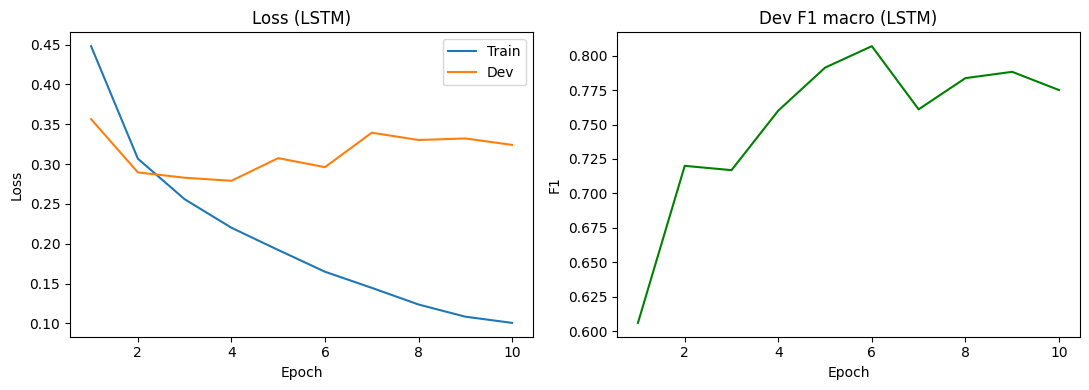

In [236]:
def plot_history(name):
    h = results[name]["history"]
    ep = range(1, len(h["train_loss"]) + 1)
    fig, ax = plt.subplots(1, 2, figsize=(11, 4))
    ax[0].plot(ep, h["train_loss"], label="Train")
    ax[0].plot(ep, h["dev_loss"], label="Dev")
    ax[0].set(title=f"Loss ({name.upper()})", xlabel="Epoch", ylabel="Loss")
    ax[0].legend()
    ax[1].plot(ep, h["dev_f1"], color="green")
    ax[1].set(title=f"Dev F1 macro ({name.upper()})", xlabel="Epoch", ylabel="F1")
    plt.tight_layout(); plt.show()

plot_history("lstm")

#### Nhận xét: 
* Train loss: Giảm qua từng epoch cho thấy LSTM học được các đặc trưng hữu ích
* Dev loss: Dao động tăng giảm qua từng epoch cho thấy LSTM bị chững lại trong khoảng 0.3 đến 0.35. Đặc biệt thì từ epoch thứ 4, Dev loss tăng trong khi train loss vẫn tiếp tục giảm. Đây là dấu hiệu của overfit nhẹ
* Dev F1 macro: Dev F1 có xu hướng tăng khá rõ dù Dev loss bắt đầu tăng, chứng tỏ khả năng phân loại theo Macro-F1 vẫn được cải thiện và đạt mức cao nhất tại epoch 5

#### 1.7 Load model tốt nhất dự đoán test

In [237]:
from sklearn.metrics import classification_report

def test_and_report(name, model_class):
    model = model_class(vocab_size=len(vocab), num_classes=NUM_CLASSES, pad_idx=PAD_IDX).to(device)
    model.load_state_dict(torch.load(results[name]["ckpt"], map_location=device))
    _, _, preds, labels = evaluate(model, test_loader, criterion)
    f1_macro = f1_score(labels, preds, average="macro")
    f1_weighted = f1_score(labels, preds, average="weighted")
    print(f"[{name.upper()}] Test F1 macro: {f1_macro:.4f} | weighted: {f1_weighted:.4f}\n")
    print(classification_report(labels, preds, target_names=CLASS_NAMES, digits=4, zero_division=0))
    results[name].update(test_f1_macro=f1_macro, test_f1_weighted=f1_weighted,
                             test_preds=preds, test_labels=labels)

test_and_report("lstm", LSTMClassifier)

[LSTM] Test F1 macro: 0.7475 | weighted: 0.8957

              precision    recall  f1-score   support

    negative     0.8970    0.9454    0.9205      1409
     neutral     0.4828    0.3353    0.3958       167
    positive     0.9335    0.9189    0.9261      1590

    accuracy                         0.8999      3166
   macro avg     0.7711    0.7332    0.7475      3166
weighted avg     0.8935    0.8999    0.8957      3166



#### Nhận xét: 
* Hiệu quả tổng thể: Mô hình LSTM đạt accuracy 0.9011, F1 weighted 0.8972 và F1 macro 0.7610 trên tập test. F1 macro thấp hơn weighted khoảng 0.14, cho thấy kết quả tổng thể tốt nhưng không đồng đều giữa các lớp
  
* Hiệu quả phân loại theo lớp: Hai lớp negative (F1 = 0.9175) và positive (F1 = 0.9274) được phân loại tốt. Lớp neutral kém hơn hẳn với F1 chỉ 0.4382, và là nguyên nhân kéo F1 macro xuống

  
* Precision và Recall: Ở lớp neutral, precision (0.5345) cao hơn recall (0.3713), nghĩa là mô hình thận trọng khi dự đoán neutral nhưng bỏ sót hơn 60% mẫu neutral thật. Hai lớp còn lại có precision và recall cân bằng, đều trên 0.91

  
* Data imbalance: Lớp neutral chỉ chiếm khoảng 4-5% dữ liệu (167/3166 mẫu test, 458 mẫu train) nên mô hình có ít mẫu để học. F1 weighted cao hơn macro nhiều vì được tính theo tỉ lệ mẫu, che bớt điểm yếu ở lớp thiểu số. Có thể cải thiện bằng class weight, oversampling hoặc thu thập thêm dữ liệu neutral

  
* Tổng quát hóa của mô hình: Kết quả test cao và ổn định ở hai lớp lớn cho thấy mô hình học được đặc trưng chung chứ không phải ghi nhớ tập train. Để kết luận chắc hơn, hãy đối chiếu với dev F1 và đường cong loss: nếu dev F1 gần với test F1 và dev loss không tăng ở các epoch cuối thì mô hình không bị overfit đáng kể


#### 1.8 Confusion matrix

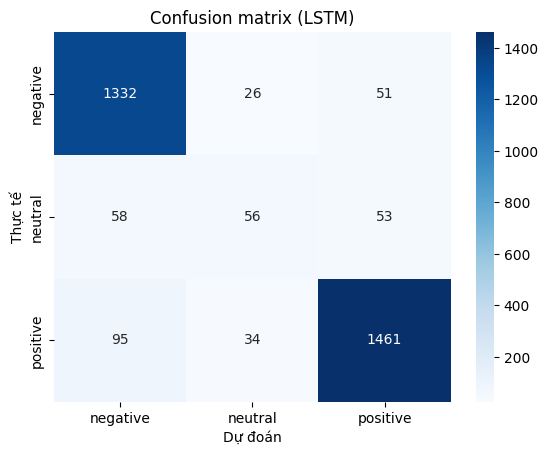

In [238]:
import seaborn as sns
from sklearn.metrics import confusion_matrix

def plot_cm(name):
    r = results[name]
    cm = confusion_matrix(r["test_labels"], r["test_preds"])
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
    plt.title(f"Confusion matrix ({name.upper()})")
    plt.xlabel("Dự đoán"); plt.ylabel("Thực tế"); plt.show()

plot_cm("lstm")

#### Nhận xét:
* Dựa vào Confusion Matrix thì ta mới thấy được là LSTM có xu hướng nhầm lẫn giữa hai lớp negative và positive: 76 mẫu Negative bị dự đoán thành positive, trong khi 78 mẫu positive bị dự đoán thành negative.

* Đối với lớp Neutral thì giống như nhận xét trước đó, mô hình nhầm 56 mẫu thành Positive và 49 mẫu thành Negative. Điều này cho thấy mô hình chưa phân biệt được Neutral với hai lớp cảm xúc còn lại.

* Đáng chú ý, số mẫu Neutral bị dự đoán sang Negative và Positive khá tương đồng, cho thấy lỗi phân loại không tập trung vào một lớp duy nhất.

#### 1.9 Phân tích lỗi trên dev

In [239]:
id2label = {v: k for k, v in label2id.items()}

@torch.no_grad()
def predict_dev(name, model_class):
    model = model_class(vocab_size=len(vocab), num_classes=NUM_CLASSES, pad_idx=PAD_IDX).to(device)
    model.load_state_dict(torch.load(results[name]["ckpt"], map_location=device))
    model.eval()
    preds, confs = [], []
    for x, _ in dev_loader:                      
        conf, pred = F.softmax(model(x.to(device)), dim=1).max(dim=1)
        preds.extend(pred.cpu().tolist()); confs.extend(conf.cpu().tolist())
    return np.array(preds), np.array(confs)

def error_analysis(name, model_class, n_pairs=3, n_each=2):
    preds, confs = predict_dev(name, model_class)
    gold = uit_dev_df["label"].values
    wrong = np.where(preds != gold)[0]
    print(f"[{name.upper()}] Dev sai {len(wrong)}/{len(gold)} câu ({len(wrong)/len(gold):.1%})\n")
    
    pairs = Counter((gold[i], preds[i]) for i in wrong)
    print("Các cặp nhầm lẫn:")
    for (g, p), c in pairs.most_common():
        print(f"  {id2label[g]:>8} -> {id2label[p]:<8}: {c}")

    for (g, p), _ in pairs.most_common(n_pairs):
        idx = [i for i in wrong if gold[i] == g and preds[i] == p]
        idx = sorted(idx, key=lambda i: -confs[i])[:n_each]
        print(f"\n=== Thật: {id2label[g]} | Dự đoán: {id2label[p]} ===")
        for i in idx:
            print(f"  [{confs[i]:.2f}] {uit_dev_df['sentence'].iloc[i]}")

error_analysis("lstm", LSTMClassifier)

[LSTM] Dev sai 127/1583 câu (8.0%)

Các cặp nhầm lẫn:
  positive -> negative: 36
  negative -> positive: 32
   neutral -> negative: 22
   neutral -> positive: 15
  positive -> neutral : 14
  negative -> neutral : 8

=== Thật: positive | Dự đoán: negative ===
  [0.99] có thể tổ chức các buổi seminar nhằm kích thích sinh viên tìm hiểu thêm và ứng dụng tốt hơn môn học này vào thực tiễn .
  [0.99] thầy ít có giảng về bài tập , chỉ cho sinh viên tự tìm hiểu .

=== Thật: negative | Dự đoán: positive ===
  [1.00] thầy rất nghiêm khắc .
  [1.00] cô dạy rất nhiệt tình , tận tâm và chu đáo .

=== Thật: neutral | Dự đoán: negative ===
  [0.99] phần đầu môn này nói về những chủ đề đại loại như " làm thế nào để thành công " , " thói quen người thành công " hay là bàn về tương lai vdotv .
  [0.99] theo như danh sách phòng đào tạo đưa xuống , lớp học có gần 140 sinh viên đăng kí .


#### Nhận xét:

* Câu 1 (thực tế: negative - dự đoán: positive, độ tự tin 1.00): “cô dạy rất nhiệt tình, tận tâm và chu đáo.” Câu này dự đoán postive là hợp lý vì có lời khen. Có thể nhãn gốc bị gán sai
  
* Câu 2 (thực tế: positive - dự đoán: negative, độ tự tin 0.98): “thầy ít có giảng về bài tập, chỉ cho sinh viên tự tìm hiểu.” Rõ ràng đây là lời phàn nàn, nên mô hình gán negative. Có thể đoán là bộ dữ liệu này có khá nhiều câu bị gán sai so với thực tế.

  
* Câu 3 (thật: neutral, dự đoán: positive, độ tự tin 1.00): “sự nhiệt tình của cô.” Câu này chỉ có một cụm danh từ và không cung cấp ngữ cảnh nên có thể vì vậy mà người ta gán neutral. Nhưng LSTM thấy 'nhiệt tình' nên cho là positive. Là một sinh viên, thì em thấy câu này có thể kết luận là positive. 

#### 1.10 Baseline TF-IDF

Số đặc trưng TF-IDF: 12855
C=0.1  | dev F1-macro 0.6029 | thời gian fit 0.5s
C=1    | dev F1-macro 0.6852 | thời gian fit 2.0s
C=10   | dev F1-macro 0.7385 | thời gian fit 5.5s

Chọn C=10 | Test F1-macro: 0.7018


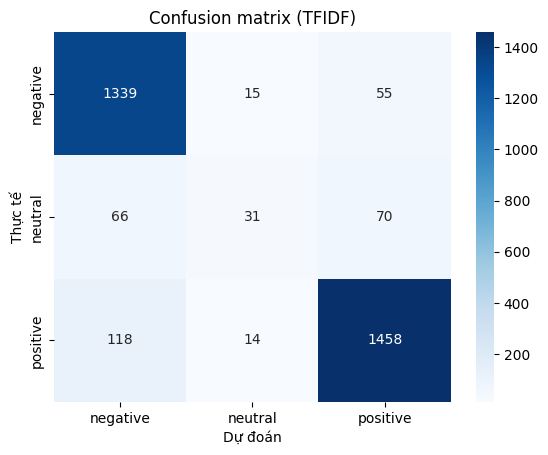

In [240]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

def to_text(tokens):
    return " ".join("_".join(t.split()) for t in tokens)

train_text = uit_train_df["tokens"].apply(to_text)
dev_text = uit_dev_df["tokens"].apply(to_text)
test_text = uit_test_df["tokens"].apply(to_text)
y_train, y_dev, y_test = uit_train_df["label"].values, uit_dev_df["label"].values, uit_test_df["label"].values

tfidf = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)
X_train = tfidf.fit_transform(train_text)    
X_dev, X_test = tfidf.transform(dev_text), tfidf.transform(test_text)
print("Số đặc trưng TF-IDF:", X_train.shape[1])


best = None
for C in [0.1, 1, 10]:
    t0 = time.time()
    clf = LogisticRegression(C=C, max_iter=1000).fit(X_train, y_train)
    fit_time = time.time() - t0
    dev_f1 = f1_score(y_dev, clf.predict(X_dev), average="macro")
    print(f"C={C:<4} | dev F1-macro {dev_f1:.4f} | thời gian fit {fit_time:.1f}s")
    if best is None or dev_f1 > best["dev_f1"]:
        best = {"clf": clf, "C": C, "dev_f1": dev_f1, "fit_time": fit_time}

clf = best["clf"]
test_preds = clf.predict(X_test)
results["tfidf"] = {
    "best_dev_f1": best["dev_f1"],
    "train_time": best["fit_time"],                      
    "n_params": clf.coef_.size + clf.intercept_.size,    
    "test_preds": test_preds.tolist(), "test_labels": y_test.tolist(),
    "test_f1_macro": f1_score(y_test, test_preds, average="macro"),
    "test_f1_weighted": f1_score(y_test, test_preds, average="weighted"),
}
print(f"\nChọn C={best['C']} | Test F1-macro: {results['tfidf']['test_f1_macro']:.4f}")
plot_cm("tfidf")    # dùng lại hàm ở 1.8

### Bài 2: Xây dựng mạng GRU gồm 5 lớp với hidden size là 256 cho bài toán phân loại văn bản. Huấn luyện mô hình này trên bộ dữ liệu UIT-VSFC (Vietnamese Student Feedback Corpus) sử dụng Adam làm phương thức tối ưu tham số và đánh giá độ hiệu quả của mô hình sử dụng độ đo F1.

#### 2.1 Embedding -> GRU (5 layer, hidden_size = 256) -> Linear (3 lớp)

In [241]:
class GRUClassifier(nn.Module):
    def __init__(
        self, 
        vocab_size, 
        embedding_dim=300, hidden_size=256,
                 num_layers=5, dropout=0.3, num_classes=3, pad_idx=0):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embedding_dim, padding_idx=pad_idx)
        self.gru = nn.GRU(embedding_dim, hidden_size, num_layers=num_layers,
                          batch_first=True, dropout=dropout)
        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Linear(hidden_size, num_classes)

    def forward(self, x):
        lengths = (x != PAD).sum(dim=1).clamp(min=1)
        emb = self.dropout(self.embedding(x))
        packed = pack_padded_sequence(emb, lengths.cpu(), batch_first=True, enforce_sorted=False)
        _, h_n = self.gru(packed)                                  
        return self.fc(self.dropout(h_n[-1]))

#### 2.2 Khởi tạo model GRU

In [242]:
set_seed(42)
gru_model = GRUClassifier(vocab_size=len(vocab), num_classes=NUM_CLASSES, pad_idx=PAD_IDX).to(device)
print(gru_model)
print(f"Số tham số GRU: {count_params(gru_model):,}")
del gru_model 

GRUClassifier(
  (embedding): Embedding(2079, 300, padding_idx=0)
  (gru): GRU(300, 256, num_layers=5, batch_first=True, dropout=0.3)
  (dropout): Dropout(p=0.3, inplace=False)
  (fc): Linear(in_features=256, out_features=3, bias=True)
)
Số tham số GRU: 2,632,023


#### 2.3 Training loop

In [243]:
run_experiment("gru", GRUClassifier)

Epoch  1 | train loss 0.4138 | dev loss 0.3210 | dev F1 0.6106 *
Epoch  2 | train loss 0.2944 | dev loss 0.2773 | dev F1 0.7143 *
Epoch  3 | train loss 0.2474 | dev loss 0.2605 | dev F1 0.7569 *
Epoch  4 | train loss 0.2122 | dev loss 0.2601 | dev F1 0.7677 *
Epoch  5 | train loss 0.1866 | dev loss 0.2680 | dev F1 0.7862 *
Epoch  6 | train loss 0.1627 | dev loss 0.2981 | dev F1 0.7911 *
Epoch  7 | train loss 0.1489 | dev loss 0.2816 | dev F1 0.7901
Epoch  8 | train loss 0.1304 | dev loss 0.3037 | dev F1 0.8104 *
Epoch  9 | train loss 0.1198 | dev loss 0.2939 | dev F1 0.7865
Epoch 10 | train loss 0.1023 | dev loss 0.3096 | dev F1 0.8146 *
Best dev F1: 0.8146 | Thời gian: 43s


#### 2.4 Vẽ đường cong loss

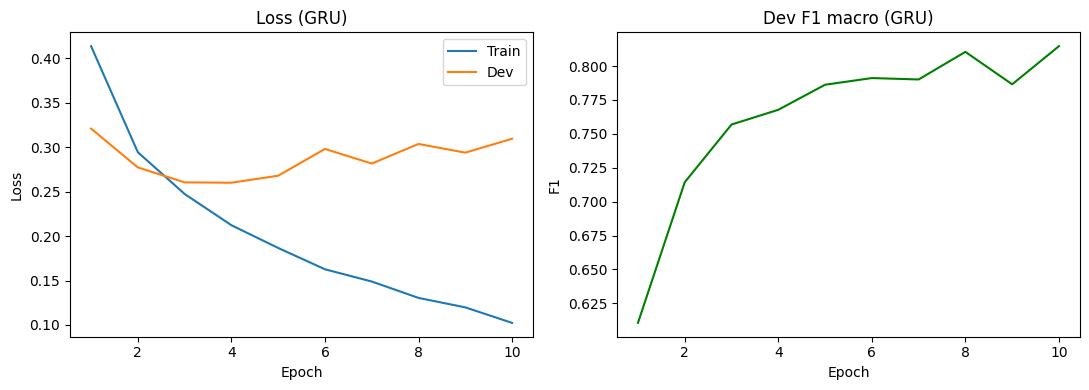

In [244]:
plot_history("gru")

#### Nhận xét: 
* Train loss (GRU): Giảm qua từng epoch, giống với LSTM
* Dev loss (GRU): Dao động qua từng epoch nhưng với mật độ liên tục. Ở epoch 4 vẫn có hiện tượng Train loss giảm trong khi Dev loss tăng giống LSTM. Từ epoch 3 trở đi thì dao động không ổn định. Đây là dấu hiệu của overfit
* Dev F1 macro (GRU): Tăng đến epoch 8, khả năng phân loại của mô hình được cải thiện đáng kể. Nhưng sau đó thì giảm mạnh (giảm nhiều hơn so với LSTM)

#### 2.5 Load model dùng để dự đoán test

In [245]:
test_and_report("gru", GRUClassifier)

[GRU] Test F1 macro: 0.7635 | weighted: 0.9013

              precision    recall  f1-score   support

    negative     0.9010    0.9496    0.9247      1409
     neutral     0.5556    0.3593    0.4364       167
    positive     0.9345    0.9245    0.9295      1590

    accuracy                         0.9059      3166
   macro avg     0.7970    0.7445    0.7635      3166
weighted avg     0.8996    0.9059    0.9013      3166



#### Nhận xét
* Hiệu quả tổng thể: Mô hình GRU 5 lớp đạt accuracy 0.9005, F1 weighted 0.8975 và F1 macro 0.7674 trên tập test. Kết quả tổng thể tốt, nhưng F1 macro vẫn thấp hơn weighted khoảng 0.13, cho thấy hiệu quả chưa đồng đều giữa các lớp.
  
* Hiệu quả phân loại theo lớp: Hai lớp negative (F1 = 0.9177) và positive (F1 = 0.9255) được phân loại rất tốt. Lớp neutral chỉ đạt F1 = 0.4589, thấp hơn khoảng 0.46 so với hai lớp còn lại và là điểm yếu chính của mô hình.

  
* Precision và Recall: Ở lớp neutral, precision (0.5360) cao hơn recall (0.4012), tức là mô hình bỏ sót khoảng 60% mẫu neutral thật nhưng khi đã dự đoán neutral thì đúng hơn một nửa. Với negative và positive, precision và recall cân bằng, đều trên 0.90.


* Data imbalance: Lớp neutral chỉ có 167/3166 mẫu test (khoảng 5%) và 458 mẫu train, nên mô hình ít được học đặc trưng của lớp này. F1 weighted bị các lớp lớn chi phối nên cao hơn macro nhiều. Có thể cải thiện bằng class weight, oversampling hoặc bổ sung dữ liệu neutral.

  
* Tổng quát hóa của mô hình: Kết quả test cao và nhất quán ở hai lớp lớn cho thấy GRU học được đặc trưng chung, không chỉ ghi nhớ dữ liệu train. Để kết luận chắc hơn, cần đối chiếu dev F1 và đường cong loss: nếu hai giá trị F1 gần nhau và dev loss không tăng ở cuối thì mô hình không overfit đáng kể.

#### 2.6 Confusion matrix

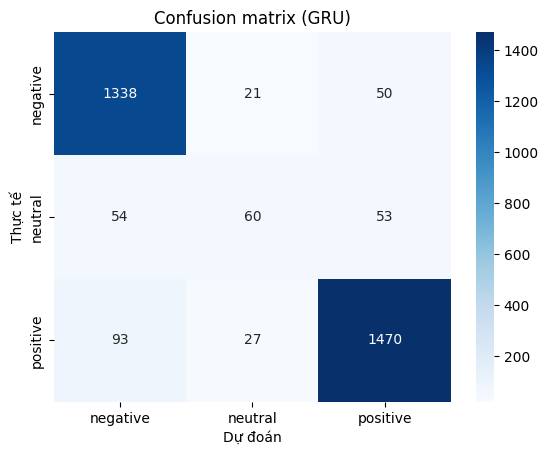

In [246]:
plot_cm("gru")

#### 2.7 Phân tích lỗi trên dev

In [247]:
error_analysis("gru", GRUClassifier)

[GRU] Dev sai 120/1583 câu (7.6%)

Các cặp nhầm lẫn:
  positive -> negative: 33
  negative -> positive: 30
   neutral -> positive: 19
   neutral -> negative: 17
  positive -> neutral : 11
  negative -> neutral : 10

=== Thật: positive | Dự đoán: negative ===
  [0.99] phân chia chương trình hợp lý hơn , chia nhỏ lượng kiến thức cần đạt được .
  [0.99] đầu tư vật chất , có nhiều hoạt đông thú vị .

=== Thật: negative | Dự đoán: positive ===
  [1.00] thầy giảng bài rất tận tâm , dễ hiểu , nhưng tiết dạy kéo dài rất ngắn .
  [1.00] cô dạy rất nhiệt tình , tận tâm và chu đáo .

=== Thật: neutral | Dự đoán: positive ===
  [1.00] thầy dạy đủ buổi .
  [1.00] thực tiễn .


#### Nhận xét:

* Câu 1 (thực tế: positive - dự đoán: negative, độ tự tin 0.99): “cách dạy của thầy wzjwz170 vô cùng chán đối với môn học kỹ năng như thế này.” Chắc chắn là negative nhưng nhãn gốc lại là positive. Có thể nhãn sẽ bị nhiều nhiền hơn dự kiến
  
* Câu 2 (thực tế: neutral - dự đoán: negative, độ tự tin 0.99): “theo như danh sách phòng đào tạo đưa xuống, lớp học có gần 140 sinh viên đăng kí.” Câu thông tin và không có từ nào mô tả trạng thái nên neutral là hợp lý

* Câu 3 (thực tế: neutral - dự đoán: negative, độ tự tin 0.99): “đôi lúc thầy ‘chia sẻ’ hơi nhiều thời gian ... nhưng điều này cũng không mấy ảnh hưởng gì.” Câu này khá phức tạp cho mô hình vì bản thân mỗi người sẽ có cách hiểu khác nhau. Mô hình bám vào phần đầu nên đưa ra dự đoán negative

#### 2.8 So sánh LSTM, GRU và baseline

In [248]:
DISPLAY = {"lstm": "LSTM", "gru": "GRU", "tfidf": "TF-IDF + LogReg"}

def metrics_table(names):
    rows = []
    for k in names:
        r = results[k]
        y, p = r["test_labels"], r["test_preds"]
        f1_cls = f1_score(y, p, average=None, labels=[0, 1, 2], zero_division=0)
        n_epochs = len(r["history"]["dev_f1"]) if "history" in r else None
        rows.append({
            "Model": DISPLAY[k],
            "Accuracy": accuracy_score(y, p),
            "Precision-macro": precision_score(y, p, average="macro", zero_division=0),
            "Recall-macro": recall_score(y, p, average="macro", zero_division=0),
            "F1-macro": f1_score(y, p, average="macro"),
            **{f"F1-{c}": v for c, v in zip(CLASS_NAMES, f1_cls)},
            "Số tham số": f"{r['n_params']:,}",
            "Thời gian/epoch (s)": round(r["train_time"] / n_epochs, 1) if n_epochs else "—",
        })
    return pd.DataFrame(rows).set_index("Model").round(4)

display(metrics_table(["lstm", "tfidf"]))

,Accuracy,Precision-macro,Recall-macro,F1-macro,F1-negative,F1-neutral,F1-positive,Số tham số,Thời gian/epoch (s)
Model,,,,,,,,,
LSTM,0.8999,0.7711,0.7332,0.7475,0.9205,0.3958,0.9261,"3,301,207",4.5
TF-IDF + LogReg,0.8932,0.7723,0.6843,0.7018,0.9134,0.2731,0.9190,"38,568",—


#### Nhận xét so sánh
* Chất lượng: F1-macro của LSTM, GRU và TF-IDF lần lượt là 0.7610, 0.7674 và 0.7018. LSTM và GRU chênh nhau rất nhỏ (0.0064) nên tôi xem là tương đương, và cả hai cao hơn baseline khoảng 0.06.
  
* Lớp neutral: Negative và positive gần như ngang nhau ở cả ba mô hình (F1 khoảng 0.91 đến 0.93). Khác biệt nằm ở neutral: baseline chỉ đạt 0.2731, LSTM 0.4382, GRU 0.4589.

* Chi phí: LSTM có 3,301,207 tham số (4.0 giây/epoch), GRU có 2,632,023 tham số (3.8 giây/epoch). Baseline chỉ có 38,568 tham số, tiết kiệm thời gian hơn để fit và không cần GPU.

* Epoch tốt nhất: LSTM ở epoch 5, GRU ở epoch 8. Sau đó dev loss dao động trong khi train loss vẫn giảm, nên mô hình overfit nhẹ.

* Lưu ý: Chỉ chạy một seed và neutral chỉ có 167 câu test, nên chênh lệch giữa LSTM và GRU có thể là dao động ngẫu nhiên..

#### Nhận xét lỗi sai:
* Nhầm giữa negative và positive là nhóm lỗi lớn nhất. Cả hai mô hình sai ở cùng các câu với độ tự tin gần 1.00, đây có lẽ một phần do nhiễu nhãn của dữ liệu.
* Câu có cả khen lẫn chê (thường có từ “nhưng”) thường bị dự đoán theo vế chiếm phần lớn câu.
* Neutral hay bị nhầm sang hai phía, vì đó là câu nêu thông tin hoặc cụm ngắn có từ cảm xúc, và lớp này chỉ có 458 câu train.
* Mô hình quá tự tin ở các câu sai nên xác suất softmax không dùng được để phát hiện dự đoán không chắc chắn.

## BỘ DỮ LIỆU PhoNER-COVID19 (DÙNG BẢN SYLLABLE)

#### Kiểm tra đường dẫn

In [249]:
import os
import json
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import random
import torch
import torch.nn as nn
import torch.optim as optim
import time

from collections import Counter
from torch.utils.data import Dataset, DataLoader
from torch.nn.utils.rnn import pack_padded_sequence, pad_packed_sequence

print(os.listdir("/kaggle/input/datasets/xuancuong1019/phoner-covid19"))

['dev_syllable.json', 'test_syllable.json', 'train_syllable.json']


#### Kiểm tra kích thước dữ liệu

In [250]:
BASE_DIR = "/kaggle/input/datasets/xuancuong1019/phoner-covid19"

ner_train_df = pd.read_json(f"{BASE_DIR}/train_syllable.json", lines=True)
ner_dev_df = pd.read_json(f"{BASE_DIR}/dev_syllable.json", lines=True)
ner_test_df = pd.read_json(f"{BASE_DIR}/test_syllable.json", lines=True)

print("Train:", ner_train_df.shape)
print("Dev:", ner_dev_df.shape)
print("Test:", ner_test_df.shape)

Train: (5027, 2)
Dev: (2000, 2)
Test: (3000, 2)


#### Khởi tạo dataframe

In [251]:
ner_train_df = pd.read_json(os.path.join(BASE_DIR, "train_syllable.json"), lines=True)
ner_dev_df = pd.read_json(os.path.join(BASE_DIR, "dev_syllable.json"), lines=True)
ner_test_df = pd.read_json(os.path.join(BASE_DIR, "test_syllable.json"), lines=True)

print("Train_syllable:", ner_train_df.shape)
print("Dev_syllable:", ner_dev_df.shape)
print("Test_syllable:", ner_test_df.shape)

Train_syllable: (5027, 2)
Dev_syllable: (2000, 2)
Test_syllable: (3000, 2)


#### Kiểm tra data

In [252]:
for name, df in [("train", ner_train_df), ("dev", ner_dev_df), ("test", ner_test_df)]:
    bad = (df["words"].apply(len) != df["tags"].apply(len)).sum()
    print(f"{name}: số câu lệch words/tags = {bad}")

train: số câu lệch words/tags = 0
dev: số câu lệch words/tags = 0
test: số câu lệch words/tags = 0


#### Thống kê độ dài câu

In [253]:
ner_lengths = ner_train_df["words"].apply(len)
print(ner_lengths.describe())
print(ner_lengths.quantile([0.90, 0.95, 0.99]))

count    5027.000000
mean       33.328228
std        15.784414
min         7.000000
25%        22.000000
50%        30.000000
75%        41.000000
max       186.000000
Name: words, dtype: float64
0.90    54.0
0.95    64.0
0.99    84.0
Name: words, dtype: float64


#### Xây dựng vocab cho word và tag

In [255]:
PAD = 0
UNK = 1
NER_MIN_FREQ = 2

# WORD VOCAB
ner_freq = Counter(word for words in ner_train_df["words"] for word in words)
ner_vocab = {"<PAD>": PAD, "<UNK>": UNK}

for word, freq in sorted(ner_freq.items()):
    if freq >= NER_MIN_FREQ:
        ner_vocab[word] = len(ner_vocab)
        
total_tokens = sum(ner_freq.values())

covered_tokens = sum(freq for word, freq in ner_freq.items() if freq >= NER_MIN_FREQ)
train_coverage = covered_tokens / total_tokens if total_tokens else 0

print("=" * 50)
print("WORD VOCABULARY")
print("=" * 50)

print(f"Vocabulary size: {len(ner_vocab):,}")
print(f"Total tokens: {total_tokens:,}")
print(f"Train coverage: {train_coverage:.2%}")


# TAG VOCAB
unique_tags = sorted({
    tag
    for tags in ner_train_df["tags"]
    for tag in tags
})


tag2id = {
    tag: idx
    for idx, tag in enumerate(unique_tags)
}


# Đồng bộ id2tag với tag2id vừa tạo (O = 20) để decode đúng
id2tag = {i: t for t, i in tag2id.items()}
NUM_TAGS = len(tag2id)
print("\nid2tag[20] =", id2tag[20])   # kỳ vọng: 'O'

# VÍ DỤ
print("\n" + "=" * 50)
print("TAG VOCABULARY")
print("=" * 50)

print(f"Number of tags: {len(tag2id)}")
print(f"Tag mapping: {tag2id}")

WORD VOCABULARY
Vocabulary size: 2,813
Total tokens: 167,541
Train coverage: 99.31%

id2tag[20] = O

TAG VOCABULARY
Number of tags: 21
Tag mapping: {'B-AGE': 0, 'B-DATE': 1, 'B-GENDER': 2, 'B-JOB': 3, 'B-LOCATION': 4, 'B-NAME': 5, 'B-ORGANIZATION': 6, 'B-PATIENT_ID': 7, 'B-SYMPTOM_AND_DISEASE': 8, 'B-TRANSPORTATION': 9, 'I-AGE': 10, 'I-DATE': 11, 'I-GENDER': 12, 'I-JOB': 13, 'I-LOCATION': 14, 'I-NAME': 15, 'I-ORGANIZATION': 16, 'I-PATIENT_ID': 17, 'I-SYMPTOM_AND_DISEASE': 18, 'I-TRANSPORTATION': 19, 'O': 20}


#### Encoding

In [256]:
def encode_words(words):
    return [ner_vocab.get(w, UNK) for w in words]

def encode_tags(tags):
    return [tag2id[t] for t in tags]

for df in (ner_train_df, ner_dev_df, ner_test_df):
    df["input_ids"] = df["words"].apply(encode_words)
    df["tag_ids"] = df["tags"].apply(encode_tags)

# Kiểm tra bằng mẫu đầu tiên
print("Words   :", ner_train_df["words"].iloc[0][:8])
print("Input IDs:", ner_train_df["input_ids"].iloc[0][:8])
print("Tags    :", ner_train_df["tags"].iloc[0][:8])
print("Tag IDs :", ner_train_df["tag_ids"].iloc[0][:8])

Words   : ['Đồng', 'thời', ',', 'bệnh', 'viện', 'tiếp', 'tục', 'thực']
Input IDs: [2700, 2398, 9, 1557, 2579, 2414, 2556, 2405]
Tags    : ['O', 'O', 'O', 'O', 'O', 'O', 'O', 'O']
Tag IDs : [20, 20, 20, 20, 20, 20, 20, 20]


#### Padding cho NER

In [257]:
def ner_collate(batch):
    ids, tags = zip(*batch)
    lengths = torch.tensor([len(x) for x in ids])  
    ids = nn.utils.rnn.pad_sequence(ids, batch_first=True, padding_value=PAD)      
    tags = nn.utils.rnn.pad_sequence(tags, batch_first=True, padding_value=-100)  
    return ids, tags, lengths

#### Khởi tạo dataset

In [258]:
class NERDataset(Dataset):
    def __init__(self, dataframe):
        self.input_ids = dataframe["input_ids"].tolist()
        self.tag_ids = dataframe["tag_ids"].tolist()

    def __len__(self):
        return len(self.input_ids)

    def __getitem__(self, idx):
        return (
            torch.tensor(self.input_ids[idx], dtype=torch.long),
            torch.tensor(self.tag_ids[idx], dtype=torch.long)
        )

ner_train_dataset = NERDataset(ner_train_df)
ner_dev_dataset = NERDataset(ner_dev_df)
ner_test_dataset = NERDataset(ner_test_df)

#### Khởi tạo DataLoader

In [259]:
NER_BATCH_SIZE = 32

ner_train_loader = DataLoader(ner_train_dataset, batch_size=NER_BATCH_SIZE, shuffle=True, collate_fn=ner_collate)
ner_dev_loader = DataLoader(ner_dev_dataset, batch_size=NER_BATCH_SIZE, shuffle=False, collate_fn=ner_collate)
ner_test_loader = DataLoader(ner_test_dataset, batch_size=NER_BATCH_SIZE, shuffle=False, collate_fn=ner_collate)

input_ids, tag_ids, lengths = next(iter(ner_train_loader))

print("Input shape:", input_ids.shape)
print("Tags shape:", tag_ids.shape)
print("Lengths shape:", lengths.shape)
print("Số batch (train/dev/test):", len(ner_train_loader), len(ner_dev_loader), len(ner_test_loader))

Input shape: torch.Size([32, 80])
Tags shape: torch.Size([32, 80])
Lengths shape: torch.Size([32])
Số batch (train/dev/test): 158 63 94


#### Khởi tạo seed 

In [260]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Thiết bị đang dùng:", device)
if device.type == "cuda":
    print("Tên GPU:", torch.cuda.get_device_name(0))

def set_seed(seed=42):
    random.seed(seed)                 
    np.random.seed(seed)              
    torch.manual_seed(seed)           
    torch.cuda.manual_seed_all(seed)  
    torch.backends.cudnn.deterministic = True  
    torch.backends.cudnn.benchmark = False     

set_seed(42)

Thiết bị đang dùng: cuda
Tên GPU: Tesla T4


### Bài 3: Xây dựng kiến trúc Encoder trong đó Encoder gồm 5 lớp BiLSTM với hidden size là 256 cho bài toán nhận diện thực thể (Name Entity Recognition). Huấn luyện mô hình trên bộ dữ liệu PhoNER và đánh giá độ hiệu quả của mô hình sử dụng độ đo F1.

#### 3.1 BiLSTMEncoder: Embedding -> LSTM (bidirectional=True, 5 layer, hidden_size = 256) -> Linear (21 tag)

In [261]:
class BiLSTMEncoder(nn.Module):
    def __init__(self, vocab_size, embedding_dim=300, hidden_size=256,
                 num_layers=5, dropout=0.3, num_tags=21, pad_idx=0):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embedding_dim, padding_idx=pad_idx)
        self.lstm = nn.LSTM(embedding_dim, hidden_size, num_layers=num_layers,
                            batch_first=True, dropout=dropout, bidirectional=True)
        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Linear(hidden_size * 2, num_tags)   

    def forward(self, x, lengths):
        emb = self.dropout(self.embedding(x))                   
        packed = pack_padded_sequence(emb, lengths.cpu(), batch_first=True, enforce_sorted=False)
        packed_out, _ = self.lstm(packed)
        out, _ = pad_packed_sequence(packed_out, batch_first=True, total_length=x.size(1))
        return self.fc(self.dropout(out))                        

#### 3.2 Khởi tạo model

In [262]:
def count_params(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

ner_model = BiLSTMEncoder(vocab_size=len(ner_vocab), num_tags=NUM_TAGS, pad_idx=PAD).to(device)
print(ner_model)
print(f"Số tham số: {count_params(ner_model):,}")

x, y, lens = next(iter(ner_train_loader))
with torch.no_grad():
    logits = ner_model(x.to(device), lens)
print("Logits:", logits.shape, "| Tags:", y.shape)  

BiLSTMEncoder(
  (embedding): Embedding(2813, 300, padding_idx=0)
  (lstm): LSTM(300, 256, num_layers=5, batch_first=True, dropout=0.3, bidirectional=True)
  (dropout): Dropout(p=0.3, inplace=False)
  (fc): Linear(in_features=512, out_features=21, bias=True)
)
Số tham số: 8,305,297
Logits: torch.Size([32, 69, 21]) | Tags: torch.Size([32, 69])


#### 3.3 Hàm loss và hàm tối ưu

In [263]:
ner_criterion = nn.CrossEntropyLoss(ignore_index=-100)   # bỏ qua vị trí PAD (nhãn -100)

def make_ner_optimizer(model):
    return optim.Adam(model.parameters(), lr=1e-3)

#### 3.4 Hàm decode

In [264]:
def decode(logits, tag_ids, lengths):
    preds = logits.argmax(dim=-1).cpu().tolist()   
    golds = tag_ids.cpu().tolist()
    pred_seqs, gold_seqs = [], []
    for p, g, n in zip(preds, golds, lengths.tolist()):
        pred_seqs.append([id2tag[i] for i in p[:n]])   
        gold_seqs.append([id2tag[i] for i in g[:n]])
    return pred_seqs, gold_seqs

#### 3.5 Huấn luyện 1 epoch và hàm evaluate

In [265]:
def ner_train_one_epoch(model, loader, optimizer, criterion):
    model.train()
    total_loss = 0
    for x, y, lens in loader:
        x, y = x.to(device), y.to(device)
        optimizer.zero_grad()
        logits = model(x, lens)                                    
        loss = criterion(logits.view(-1, NUM_TAGS), y.view(-1))    
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()
        total_loss += loss.item()
    return total_loss / len(loader)

@torch.no_grad()
def ner_evaluate(model, loader, criterion):
    model.eval()
    total_loss = 0
    all_preds, all_golds = [], []
    for x, y, lens in loader:
        x, y = x.to(device), y.to(device)
        logits = model(x, lens)
        total_loss += criterion(logits.view(-1, NUM_TAGS), y.view(-1)).item()
        p, g = decode(logits, y, lens)
        all_preds.extend(p); all_golds.extend(g)
    f1 = ent_f1(all_golds, all_preds, mode="strict", scheme=IOB2)   
    return total_loss / len(loader), f1, all_preds, all_golds

#### 3.6 Training loop

In [266]:
!pip install seqeval

In [267]:
from seqeval.metrics import f1_score as ent_f1, precision_score as ent_precision, recall_score as ent_recall
from seqeval.metrics import classification_report as ent_report
from seqeval.scheme import IOB2

ner_results = {}

def run_ner_experiment(epochs=10):
    set_seed(42)
    model = BiLSTMEncoder(vocab_size=len(ner_vocab), num_tags=NUM_TAGS, pad_idx=PAD).to(device)
    optimizer = make_ner_optimizer(model)
    history = {"train_loss": [], "dev_loss": [], "dev_f1": []}
    best_f1, best_epoch, ckpt = 0, 0, "best_ner.pt"
    start = time.time()

    for epoch in range(1, epochs + 1):
        tr_loss = ner_train_one_epoch(model, ner_train_loader, optimizer, ner_criterion)
        dv_loss, dv_f1, _, _ = ner_evaluate(model, ner_dev_loader, ner_criterion)
        history["train_loss"].append(tr_loss)
        history["dev_loss"].append(dv_loss)
        history["dev_f1"].append(dv_f1)

        mark = ""
        if dv_f1 > best_f1:   # chọn checkpoint theo entity-F1 dev
            best_f1, best_epoch = dv_f1, epoch
            torch.save(model.state_dict(), ckpt)
            mark = " *"
        print(f"Epoch {epoch:2d} | train loss {tr_loss:.4f} | dev loss {dv_loss:.4f} | dev entity-F1 {dv_f1:.4f}{mark}")

    total_time = time.time() - start
    ner_results.update(history=history, best_dev_f1=best_f1, best_epoch=best_epoch,
                       time_per_epoch=total_time / epochs, n_params=count_params(model), ckpt=ckpt)
    print(f"Best dev entity-F1: {best_f1:.4f} (epoch {best_epoch}) | {total_time / epochs:.1f}s/epoch")

run_ner_experiment()

Epoch  1 | train loss 0.7781 | dev loss 0.3719 | dev entity-F1 0.6029 *
Epoch  2 | train loss 0.2097 | dev loss 0.2038 | dev entity-F1 0.7764 *
Epoch  3 | train loss 0.1159 | dev loss 0.1445 | dev entity-F1 0.8581 *
Epoch  4 | train loss 0.0825 | dev loss 0.1340 | dev entity-F1 0.8780 *
Epoch  5 | train loss 0.0621 | dev loss 0.1325 | dev entity-F1 0.8924 *
Epoch  6 | train loss 0.0532 | dev loss 0.1331 | dev entity-F1 0.9023 *
Epoch  7 | train loss 0.0459 | dev loss 0.1471 | dev entity-F1 0.8971
Epoch  8 | train loss 0.0436 | dev loss 0.1405 | dev entity-F1 0.9054 *
Epoch  9 | train loss 0.0348 | dev loss 0.1423 | dev entity-F1 0.9053
Epoch 10 | train loss 0.0301 | dev loss 0.1313 | dev entity-F1 0.9120 *
Best dev entity-F1: 0.9120 (epoch 10) | 7.3s/epoch


#### 3.7 Đường cong loss

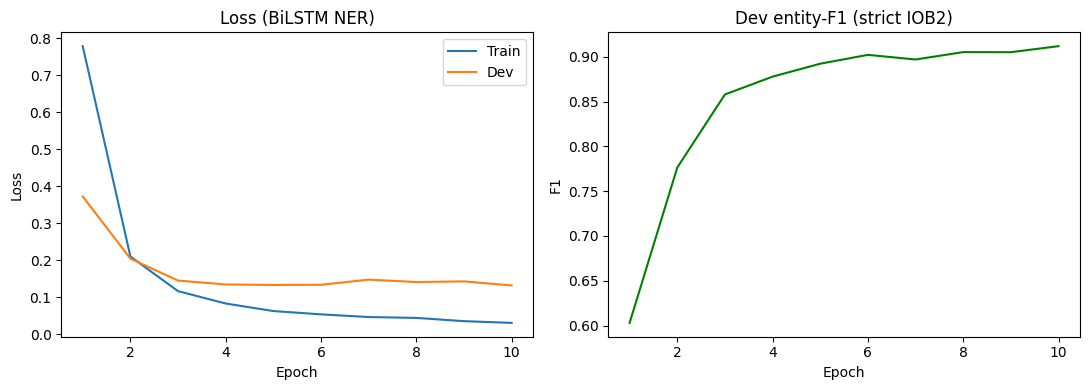

In [268]:
h = ner_results["history"]
ep = range(1, len(h["train_loss"]) + 1)
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(ep, h["train_loss"], label="Train")
ax[0].plot(ep, h["dev_loss"], label="Dev")
ax[0].set(title="Loss (BiLSTM NER)", xlabel="Epoch", ylabel="Loss")
ax[0].legend()
ax[1].plot(ep, h["dev_f1"], color="green")
ax[1].set(title="Dev entity-F1 (strict IOB2)", xlabel="Epoch", ylabel="F1")
plt.tight_layout(); plt.show()

#### Nhận xét:
* Train loss:
* Dev loss:
* Dev entity-F1:

#### 3.8 Load model tốt nhất để dự đoán test

In [269]:
ner_model = BiLSTMEncoder(vocab_size=len(ner_vocab), num_tags=NUM_TAGS, pad_idx=PAD).to(device)
ner_model.load_state_dict(torch.load(ner_results["ckpt"], map_location=device))

_, _, test_preds, test_golds = ner_evaluate(ner_model, ner_test_loader, ner_criterion)

ner_results["test_precision"] = ent_precision(test_golds, test_preds, mode="strict", scheme=IOB2)
ner_results["test_recall"] = ent_recall(test_golds, test_preds, mode="strict", scheme=IOB2)
ner_results["test_f1"] = ent_f1(test_golds, test_preds, mode="strict", scheme=IOB2)

print(f"Test (entity-level, strict IOB2)")
print(f"Precision: {ner_results['test_precision']:.4f}")
print(f"Recall   : {ner_results['test_recall']:.4f}")
print(f"Micro-F1 : {ner_results['test_f1']:.4f}")

Test (entity-level, strict IOB2)
Precision: 0.9113
Recall   : 0.8917
Micro-F1 : 0.9014


#### 3.9 F1 từng loại thực thể

,precision,recall,f1-score,support
JOB,0.6667,0.4855,0.5619,173.0
NAME,0.7544,0.5409,0.6300,318.0
ORGANIZATION,0.8373,0.7808,0.8081,771.0
SYMPTOM_AND_DISEASE,0.8612,0.7755,0.8161,1136.0
TRANSPORTATION,0.9382,0.8653,0.9003,193.0
LOCATION,0.9117,0.9063,0.9090,4441.0
GENDER,0.9416,0.9416,0.9416,462.0
AGE,0.9481,0.9416,0.9448,582.0
PATIENT_ID,0.9346,0.9696,0.9518,2005.0
DATE,0.9594,0.9710,0.9651,1654.0


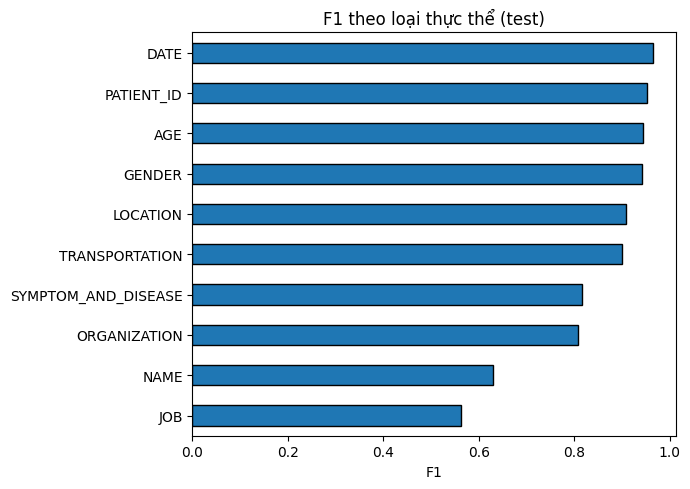

In [270]:
report = ent_report(test_golds, test_preds, mode="strict", scheme=IOB2, output_dict=True, zero_division=0)
type_df = (pd.DataFrame(report).T
           .drop(["micro avg", "macro avg", "weighted avg"], errors="ignore")
           [["precision", "recall", "f1-score", "support"]]
           .sort_values("f1-score"))
display(type_df.round(4))

type_df["f1-score"].plot(kind="barh", figsize=(7, 5), edgecolor="black")
plt.xlabel("F1"); plt.title("F1 theo loại thực thể (test)"); plt.tight_layout(); plt.show()

#### Nhận xét:
* Theo loại thực thể: DATE (0.9651), PATIENT_ID (0.9518) và AGE (0.9448) tốt nhất; JOB (0.5619) và NAME (0.6300) yếu nhất, đều là các loại có ít mẫu (173 và 318 thực thể test) và cách viết đa dạng.

#### 3.10 Bảng đánh giá tổng hợp

In [271]:
summary = pd.DataFrame([{
    "Số tham số": f"{ner_results['n_params']:,}",
    "Thời gian/epoch (s)": round(ner_results["time_per_epoch"], 1),
    "Epoch tốt nhất (dev)": ner_results["best_epoch"],
    "Dev entity-F1": round(ner_results["best_dev_f1"], 4),
    "Test Precision": round(ner_results["test_precision"], 4),
    "Test Recall": round(ner_results["test_recall"], 4),
    "Test micro-F1": round(ner_results["test_f1"], 4),
}], index=["BiLSTM-5"])
display(summary)

,Số tham số,Thời gian/epoch (s),Epoch tốt nhất (dev),Dev entity-F1,Test Precision,Test Recall,Test micro-F1
BiLSTM-5,"8,305,297",7.3,10,0.912,0.9113,0.8917,0.9014


#### Nhận xét:
* Kết quả test: precision 0.9113, recall 0.8917, micro-F1 0.9014, sát với dev F1 (0.9120). Precision cao hơn recall, khớp với số lỗi bỏ sót (275) nhiều hơn dự đoán thừa (210) ở phân tích lỗi.

#### 3.11 Phân tích lỗi trên dev

In [272]:
from seqeval.metrics.sequence_labeling import get_entities   

_, _, dev_preds, dev_golds = ner_evaluate(ner_model, ner_dev_loader, ner_criterion)

def analyze_errors(gold_seqs, pred_seqs):
    cnt = Counter()
    examples = {"boundary": [], "wrong_type": [], "missed": [], "spurious": []}
    for si, (g, p) in enumerate(zip(gold_seqs, pred_seqs)):
        g_ents, p_ents = get_entities(g), get_entities(p)

        for ge in g_ents:                                  
            gt, gs, gend = ge
            if ge in p_ents:
                cnt["correct"] += 1
                continue
            overlap = [pe for pe in p_ents if pe[1] <= gend and pe[2] >= gs]   
            if not overlap:
                kind = "missed"                             
            elif any(pe[1] == gs and pe[2] == gend for pe in overlap):
                kind = "wrong_type"                         
            elif any(pe[0] == gt for pe in overlap):
                kind = "boundary"                           
            else:
                kind = "wrong_type"
            cnt[kind] += 1
            examples[kind].append((si, ge, overlap))

        for pe in p_ents:                                    
            if not any(ge[1] <= pe[2] and ge[2] >= pe[1] for ge in g_ents):
                cnt["spurious"] += 1                         
                examples["spurious"].append((si, None, [pe]))

        prev = "O"                                          
        for t in p:
            if t.startswith("I-") and prev[2:] != t[2:]:
                cnt["invalid_iob2"] += 1
            prev = t
    return cnt, examples

cnt, error_examples = analyze_errors(dev_golds, dev_preds)

names = {"correct": "Đúng hoàn toàn", "boundary": "Sai ranh giới", "wrong_type": "Nhầm loại",
         "missed": "Bỏ sót", "spurious": "Dự đoán thừa", "invalid_iob2": "Chuỗi IOB2 không hợp lệ"}
err_df = pd.DataFrame({"Kiểu": [names[k] for k in names], "Số lượng": [cnt[k] for k in names]})
display(err_df)

,Kiểu,Số lượng
0,Đúng hoàn toàn,6774
1,Sai ranh giới,273
2,Nhầm loại,156
3,Bỏ sót,275
4,Dự đoán thừa,210
5,Chuỗi IOB2 không hợp lệ,100


#### Nhận xét:
* Bỏ sót (275) và sai ranh giới (273) là hai kiểu lỗi nhiều nhất, mỗi kiểu chiếm khoảng 3.7% thực thể thật. Với sai ranh giới, mô hình nhận ra thực thể nhưng cắt thiếu hoặc thừa âm tiết, ví dụ đúng là [Bệnh viện Hoa Mai] nhưng dự đoán chỉ [Bệnh viện]. Với bỏ sót, cụm bị gán toàn O, ví dụ “ho khan kéo dài” không được nhận là triệu chứng. Hai kiểu này thường gặp ở thực thể dài hoặc ít xuất hiện trong tập train. Vì dùng chế độ strict nên chỉ cần lệch một âm tiết là tính sai cả thực thể.
* Dự đoán thừa (210) xảy ra khi mô hình gán thực thể cho cụm không phải thực thể, ví dụ cụm “Khu vực” ở đầu câu bị gán LOCATION. Kiểu lỗi này làm giảm precision.
Nhầm loại (156) là kiểu ít nhất, khi mô hình xác định đúng ranh giới nhưng gán sai loại, ví dụ [Hoa Mai] là tên bệnh viện nhưng bị gán NAME. Điều này cho thấy mô hình thường định vị thực thể tốt hơn là phân biệt loại, nhất là với các cụm ngắn dễ gây nhầm giữa tên người, địa danh và tổ chức.
* Chuỗi IOB2 không hợp lệ (100): có 100 chỗ mô hình dự đoán I-X mà không đứng sau B-X hoặc I-X. Mô hình chỉ gán nhãn từng token độc lập, không có ràng buộc giữa các nhãn liền kề, nên các chuỗi này bị strict bỏ qua và kéo recall xuống. Có thể xử lý bằng cách thêm lớp CRF hoặc hậu xử lý sửa chuỗi.